In [ ]:
r'C:\Users\usER\Downloads\tb_xray_data\TB_Chest_Radiography_Database'

In [7]:
import scipy.io
import os
import numpy as np
import imageio

input_folder = r'C:\Users\usER\Downloads\BrainTumorDataset'
output_folder = "converted_images"

os.makedirs(output_folder, exist_ok=True)

for file_name in os.listdir(input_folder):
    if file_name.endswith(".mat"):
        mat = scipy.io.loadmat(os.path.join(input_folder, file_name))
        cjdata = mat['cjdata']
        
        image = cjdata['image'][0][0]
        label = int(cjdata['label'][0][0][0][0])  # 1, 2, or 3
        
        # Normalize image to 0–255
        image = image.astype(np.float32)
        image = (255 * (image - image.min()) / (image.max() - image.min())).astype(np.uint8)

        label_folder = os.path.join(output_folder, str(label))
        os.makedirs(label_folder, exist_ok=True)

        image_name = os.path.splitext(file_name)[0] + ".jpg"
        imageio.imwrite(os.path.join(label_folder, image_name), image)


NotImplementedError: Please use HDF reader for matlab v7.3 files, e.g. h5py

In [8]:
input_folder = r'C:\Users\usER\Downloads\BrainTumorDataset'
output_folder = "converted_images"
file_list = dir(fullfile(input_folder, '*.mat')); 
for i = 1:numel(file_list)
    file_name = file_list(i).name;
    file_path = fullfile(input_folder, file_name);
    
    mat_data = load(file_path);  
    cjdata = mat_data.cjdata;
    
    im1 = double(cjdata.image); 
    min1 = min(im1(:));
    max1 = max(im1(:));
    im = uint8(255/(max1-min1)*(im1-min1));
    label = cjdata.label;  
    
    label_folder = fullfile(output_folder, num2str(label));
    if ~exist(label_folder, 'dir')
        mkdir(label_folder); 
    end
    
    [~, file_name_base, ~] = fileparts(file_name);
    output_file_path = fullfile(label_folder, strcat(file_name_base, '.jpg'));
    
    imwrite(im, output_file_path);  
end

SyntaxError: invalid syntax (3351074745.py, line 4)

In [10]:
import h5py
import os
import numpy as np
import imageio

input_folder = r'C:\Users\usER\Downloads\BrainTumorDataset'
output_folder = "converted_images"

os.makedirs(output_folder, exist_ok=True)

for file_name in os.listdir(input_folder):
    if file_name.endswith(".mat"):
        file_path = os.path.join(input_folder, file_name)
        
        with h5py.File(file_path, 'r') as f:
            # Access nested HDF5 data format
            cjdata = f['cvind']

            image = np.array(cjdata['image']).T  # transpose to fix orientation
            label = int(np.array(cjdata['label'])[0][0])

            # Normalize image to 0–255
            image = image.astype(np.float32)
            image = (255 * (image - image.min()) / (image.max() - image.min())).astype(np.uint8)

            label_folder = os.path.join(output_folder, str(label))
            os.makedirs(label_folder, exist_ok=True)

            image_name = os.path.splitext(file_name)[0] + ".jpg"
            imageio.imwrite(os.path.join(label_folder, image_name), image)


ValueError: Field names only allowed for compound types

In [12]:
import os
import zipfile
import h5py
import numpy as np
import imageio

# Step 1: Define paths
dataset_dir = r'C:\Users\usER\Downloads\1512427'
output_dir = os.path.join(dataset_dir, "converted_images")
os.makedirs(output_dir, exist_ok=True)

# Step 2: Extract ZIP files
for file in os.listdir(dataset_dir):
    if file.endswith(".zip"):
        zip_path = os.path.join(dataset_dir, file)
        extract_folder = os.path.join(dataset_dir, os.path.splitext(file)[0])
        os.makedirs(extract_folder, exist_ok=True)

        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_folder)
        print(f"Extracted {file} to {extract_folder}")

# Step 3: Process .mat files in all extracted folders
for root, _, files in os.walk(dataset_dir):
    for file in files:
        if file.endswith(".mat") and file != "cvind.mat":
            file_path = os.path.join(root, file)
            try:
                with h5py.File(file_path, 'r') as f:
                    cjdata = f['cjdata']

                    image = np.array(cjdata['image']).T  # Transpose to fix orientation
                    label = int(np.array(cjdata['label'])[0][0])  # 1, 2, or 3

                    # Normalize image to 0-255
                    image = image.astype(np.float32)
                    image = (255 * (image - image.min()) / (image.max() - image.min())).astype(np.uint8)

                    # Save image
                    label_folder = os.path.join(output_dir, str(label))
                    os.makedirs(label_folder, exist_ok=True)

                    image_name = os.path.splitext(file)[0] + ".jpg"
                    output_path = os.path.join(label_folder, image_name)
                    imageio.imwrite(output_path, image)

            except Exception as e:
                print(f"Error processing {file_path}: {e}")

print("✅ All images converted and saved in:", output_dir)


✅ All images converted and saved in: C:\Users\usER\Downloads\1512427\converted_images


In [13]:
!pip install h5py imageio


Defaulting to user installation because normal site-packages is not writeable


In [14]:
import os
import h5py
import numpy as np
import imageio

input_root = r'C:\Users\usER\Downloads\BrainTumorDataset'  # Adjust this if needed
output_folder = r'C:\Users\usER\Downloads\1512427\converted_images'

os.makedirs(output_folder, exist_ok=True)

saved_count = 0

# Walk through all subfolders to find .mat files
for root, dirs, files in os.walk(input_root):
    for file in files:
        if file.endswith('.mat'):
            file_path = os.path.join(root, file)
            try:
                with h5py.File(file_path, 'r') as f:
                    cjdata = f['cjdata']

                    # Load and transpose image matrix
                    image = np.array(cjdata['image']).T
                    label = int(np.array(cjdata['label'])[0][0])  # Should be 1, 2, or 3

                    # Normalize to 0–255
                    image = image.astype(np.float32)
                    image = (255 * (image - image.min()) / (image.max() - image.min())).astype(np.uint8)

                    # Save in corresponding label folder
                    label_folder = os.path.join(output_folder, str(label))
                    os.makedirs(label_folder, exist_ok=True)

                    image_name = os.path.splitext(file)[0] + '.jpg'
                    save_path = os.path.join(label_folder, image_name)
                    imageio.imwrite(save_path, image)

                    saved_count += 1
                    print(f"✅ Saved: {save_path}")

            except Exception as e:
                print(f"❌ Error in {file_path}: {e}")

print(f"\n✅ All images converted and saved: {saved_count}")
print(f"📁 Location: {output_folder}")


[3,064 per-file 'Saved' messages removed for readability]
❌ Error in C:\Users\usER\Downloads\BrainTumorDataset\cvind.mat: "Unable to synchronously open object (object 'cjdata' doesn't exist)"


[3,064 per-file 'Saved' messages removed for readability]


[3,064 per-file 'Saved' messages removed for readability]


[3,064 per-file 'Saved' messages removed for readability]


[3,064 per-file 'Saved' messages removed for readability]


[3,064 per-file 'Saved' messages removed for readability]


... (15 outputs left out)

[3,064 per-file 'Saved' messages removed for readability]


[3,064 per-file 'Saved' messages removed for readability]


[3,064 per-file 'Saved' messages removed for readability]


[3,064 per-file 'Saved' messages removed for readability]

✅ All images converted and saved: 3064
📁 Location: C:\Users\usER\Downloads\1512427\converted_images


In [15]:
import os
import shutil
import random

# Set seed for reproducibility
random.seed(42)

# Paths
source_dir = r'C:\Users\usER\Downloads\1512427\converted_images'
output_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'

# Split ratios
train_ratio = 0.7
val_ratio = 0.15
test_ratio = 0.15

# Create output directories
for split in ['train', 'val', 'test']:
    for class_name in os.listdir(source_dir):
        class_path = os.path.join(source_dir, class_name)
        if os.path.isdir(class_path):
            os.makedirs(os.path.join(output_dir, split, class_name), exist_ok=True)

# Split each class
for class_name in os.listdir(source_dir):
    class_path = os.path.join(source_dir, class_name)
    if not os.path.isdir(class_path):
        continue
    
    # List and shuffle images
    images = os.listdir(class_path)
    random.shuffle(images)

    total = len(images)
    train_end = int(train_ratio * total)
    val_end = train_end + int(val_ratio * total)

    splits = {
        'train': images[:train_end],
        'val': images[train_end:val_end],
        'test': images[val_end:]
    }

    # Move files into corresponding folders
    for split, files in splits.items():
        for file in files:
            src = os.path.join(class_path, file)
            dst = os.path.join(output_dir, split, class_name, file)
            shutil.copyfile(src, dst)

print("✅ Done! Images are split into train, val, and test.")
print(f"Path: {output_dir}")


✅ Done! Images are split into train, val, and test.
Path: C:\Users\usER\Downloads\1512427\converted_images_split


In [16]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

data_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'
img_height, img_width = 224, 224
batch_size = 32

datagen = ImageDataGenerator(rescale=1./255)

train_data = datagen.flow_from_directory(
    os.path.join(data_dir, 'train'),
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical'
)

val_data = datagen.flow_from_directory(
    os.path.join(data_dir, 'val'),
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical'
)

test_data = datagen.flow_from_directory(
    os.path.join(data_dir, 'test'),
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)


Found 2144 images belonging to 3 classes.
Found 458 images belonging to 3 classes.
Found 462 images belonging to 3 classes.


Found 2144 images belonging to 3 classes.
Found 458 images belonging to 3 classes.
Found 462 images belonging to 3 classes.
Epoch 1/10


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



Epoch 1: val_loss improved from inf to 0.38953, saving model to best_model.keras
67/67 - 90s - 1s/step - accuracy: 0.7062 - loss: 0.6891 - val_accuracy: 0.8690 - val_loss: 0.3895
Epoch 2/10

Epoch 2: val_loss improved from 0.38953 to 0.34727, saving model to best_model.keras
67/67 - 64s - 958ms/step - accuracy: 0.8442 - loss: 0.3980 - val_accuracy: 0.8603 - val_loss: 0.3473
Epoch 3/10

Epoch 3: val_loss improved from 0.34727 to 0.33038, saving model to best_model.keras
67/67 - 62s - 928ms/step - accuracy: 0.8797 - loss: 0.3255 - val_accuracy: 0.8646 - val_loss: 0.3304
Epoch 4/10

Epoch 4: val_loss did not improve from 0.33038
67/67 - 83s - 1s/step - accuracy: 0.8848 - loss: 0.2950 - val_accuracy: 0.8690 - val_loss: 0.3329
Epoch 5/10

Epoch 5: val_loss improved from 0.33038 to 0.31585, saving model to best_model.keras
67/67 - 72s - 1s/step - accuracy: 0.8974 - loss: 0.2565 - val_accuracy: 0.8668 - val_loss: 0.3159
Epoch 6/10

Epoch 6: val_loss improved from 0.31585 to 0.31499, saving m

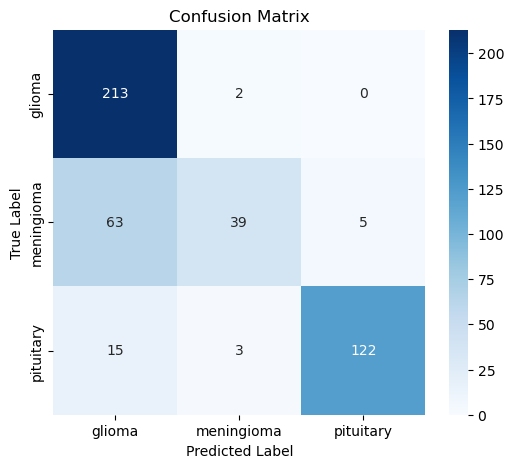

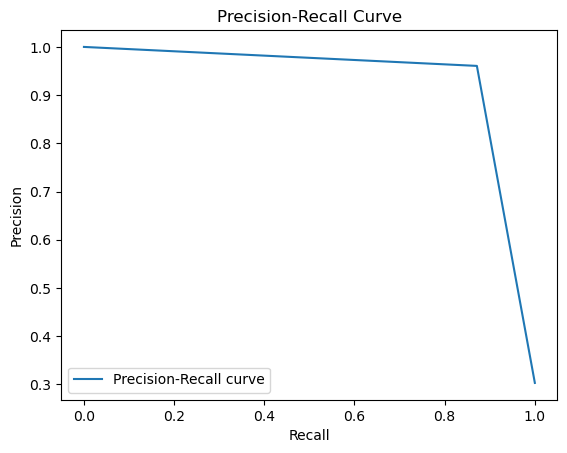

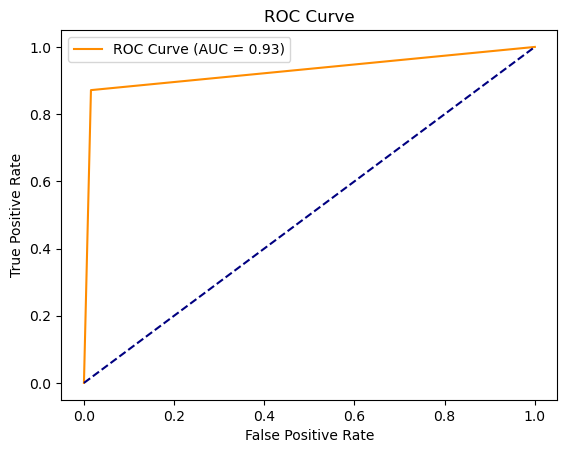

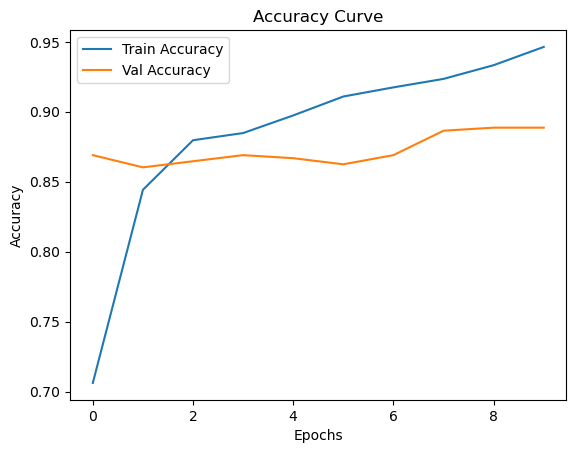

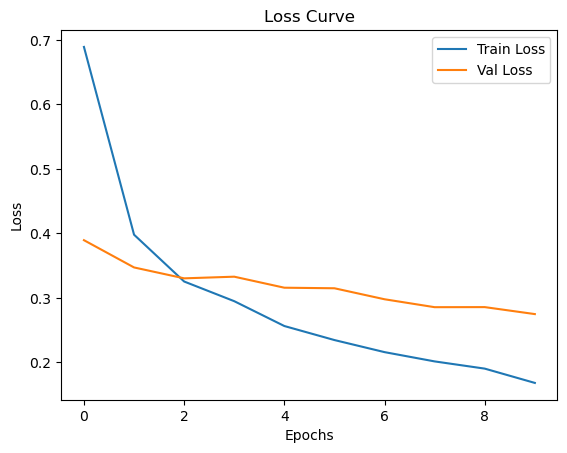

In [19]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, roc_curve, auc, confusion_matrix, classification_report
import seaborn as sns
import os

# Base data directory
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'

# Paths
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# Image parameters
img_height, img_width = 224, 224
batch_size = 32

# ImageDataGenerator (rescale only)
datagen = ImageDataGenerator(rescale=1./255)

# Load data
train_data = datagen.flow_from_directory(
    train_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True
)

val_data = datagen.flow_from_directory(
    val_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True
)

test_data = datagen.flow_from_directory(
    test_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

# Model setup
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(3, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=x)

model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train
history = model.fit(
    train_data,
    epochs=10,
    validation_data=val_data,
    callbacks=[checkpoint, early_stopping],
    verbose=2
)

# Fine-tune (unfreeze last 100 layers)
base_model.trainable = True
for layer in base_model.layers[:-100]:
    layer.trainable = False

model.compile(optimizer=Adam(learning_rate=1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

history_finetune = model.fit(
    train_data,
    epochs=10,
    validation_data=val_data,
    callbacks=[checkpoint, early_stopping],
    verbose=2
)

# Evaluation on test set
test_loss, test_acc = model.evaluate(test_data)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Predictions
test_labels = test_data.classes
test_preds = model.predict(test_data)
test_preds = np.argmax(test_preds, axis=1)

# Confusion Matrix and Report
conf_matrix = confusion_matrix(test_labels, test_preds)
print("\nConfusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(classification_report(test_labels, test_preds, target_names=test_data.class_indices.keys()))

# Confusion Matrix Plot
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_data.class_indices.keys(),
            yticklabels=test_data.class_indices.keys())
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Precision-Recall (for class index 2, you can change)
precision, recall, _ = precision_recall_curve(test_labels == 2, test_preds == 2)
plt.figure()
plt.plot(recall, precision, label='Precision-Recall curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(test_labels == 2, test_preds == 2)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='darkorange')
plt.plot([0, 1], [0, 1], linestyle='--', color='navy')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Plot Accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [29]:
model.save('final1_mobilenetv2_tb_model.h5')  # Save the model
print("Model saved successfully!")


Model saved successfully!


In [28]:
model.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

Total params: 3,572,805 (13.63 MB)

Trainable params: 3,483,203 (13.29 MB)

Non-trainable params: 89,600 (350.00 KB)

Optimizer params: 2 (12.00 B)

In [7]:
!pip install tensorflow opencv-python matplotlib numpy


Defaulting to user installation because normal site-packages is not writeable


In [18]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import os
import random


In [154]:
from tensorflow.keras.models import load_model

# Load trained model
model = load_model("mobilenetv2 model _10 epochs.h5")
print("✅ Model Loaded")


✅ Model Loaded


In [315]:
def preprocess_image(image_path):
    img = tf.keras.preprocessing.image.load_img(image_path, target_size=(224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # Expand to batch size (1, 224, 224, 3)
    img_array = img_array / 255.0  # Rescale to match training preprocessing
    return img_array

img_array = preprocess_image(image_path)



In [316]:
def compute_gradcam(model, img_array, layer_name="block_16_project"):
    """
    Generate Grad-CAM heatmap for a given image using MobileNetV2.

    Args:
        model: The trained Functional model (MobileNetV2 or similar).
        img_array: Preprocessed image array (shape: [1, 224, 224, 3]).
        layer_name: The name of the convolutional layer to generate Grad-CAM from.

    Returns:
        heatmap: The Grad-CAM heatmap (normalized, 2D).
    """
    # 🔹 Step 1: Create a model that maps input to activations & predictions
    grad_model = tf.keras.models.Model(
        inputs=model.input,
        outputs=[model.get_layer(layer_name).output, model.output]
    )

    # 🔹 Step 2: Forward + Backward pass
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]  # for binary classification

    # 🔹 Step 3: Compute gradients
    grads = tape.gradient(loss, conv_outputs)

    # 🔹 Step 4: Compute guided weights
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # 🔹 Step 5: Compute the heatmap
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(tf.multiply(pooled_grads, conv_outputs), axis=-1)

    # 🔹 Step 6: Normalize the heatmap
    heatmap = np.maximum(heatmap, 0)
    heatmap /= np.max(heatmap) + 1e-8  # avoid division by zero

    return heatmap



In [317]:
def overlay_heatmap(image_path, heatmap, alpha=0.5, colormap=cv2.COLORMAP_JET):
    """
    Overlay the Grad-CAM heatmap on the original image with corrected colors.
    
    Args:
        image_path: Path to the original image.
        heatmap: Generated Grad-CAM heatmap (normalized between 0 and 1).
        alpha: Transparency factor for heatmap overlay.
        colormap: OpenCV colormap for visualization.
    """
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))  # Resize to 224x224

    # Normalize heatmap
    heatmap = np.maximum(heatmap, 0)
    heatmap /= np.max(heatmap) + 1e-8  # Normalize

    # Invert the heatmap colors (high activation should be RED)
    heatmap =0.5  - heatmap  # Invert so high values become low (mapped to blue)

    # Apply heatmap coloring
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))  # Resize to image size
    heatmap = np.uint8(255 * heatmap)  # Convert to range [0,255]
    heatmap = cv2.applyColorMap(heatmap, colormap)  # Apply chosen colormap

    # Superimpose the heatmap on the original image
    superimposed_img = cv2.addWeighted(img, 1 - alpha, heatmap, alpha, 0)

    # Display the final image
    plt.figure(figsize=(6, 6))
    plt.imshow(superimposed_img)
    plt.axis('off')
    plt.show()

In [318]:
import tensorflow as tf
import numpy as np

def preprocess_image(image_path, target_size=(224, 224), normalize=True):
    """
    Load and preprocess an image from disk for model prediction.
    
    Args:
        image_path (str): Path to the image file.
        target_size (tuple): Target size to resize the image (default is 224x224).
        normalize (bool): Whether to normalize pixel values to [0, 255].

    Returns:
        np.ndarray: Preprocessed image array with shape (1, height, width, channels).
    """
    # 🔹 Step 1: Load and resize the image
    img = tf.keras.preprocessing.image.load_img(image_path, target_size=target_size)
    
    # 🔹 Step 2: Convert to NumPy array
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    
    # 🔹 Step 3: Expand dimensions to match batch size
    img_array = np.expand_dims(img_array, axis=0)  # Shape: (1, H, W, C)
    
    # 🔹 Step 4: Normalize pixel values if required
    if normalize:
        img_array = img_array / 255.0

    return img_array


In [432]:
# 🔹 Define the base directory where images are stored
base_path = r'C:\Users\usER\Downloads\1512427\converted_images_split\train\pituitary'

# 🔹 Predefine the specific image
default_image = "1166.jpg"

# 🔹 Ask the user to use the default image or choose another
print("Press Enter to use the default image (1166.jpg), or type 'random' to select a random image.")
print("Alternatively, enter a filename from the folder.")

# 🔹 List all available images in the folder
image_files = [f for f in os.listdir(base_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

# Get user input
user_choice = input("\nEnter filename or 'random': ").strip()

if user_choice == "":
    selected_image = default_image  # Use predefined image
elif user_choice.lower() == "random":
    selected_image = random.choice(image_files)  # Random selection
elif user_choice in image_files:
    selected_image = user_choice  # Use the user-provided filename
else:
    print("Invalid choice. Using the default image instead.")
    selected_image = default_image

# Build the full path to the selected image
image_path = os.path.join(base_path, selected_image)
print("Using image:", image_path)


Press Enter to use the default image (1166.jpg), or type 'random' to select a random image.
Alternatively, enter a filename from the folder.

Enter filename or 'random': 1279.jpg
Using image: C:\Users\usER\Downloads\1512427\converted_images_split\train\pituitary\1279.jpg


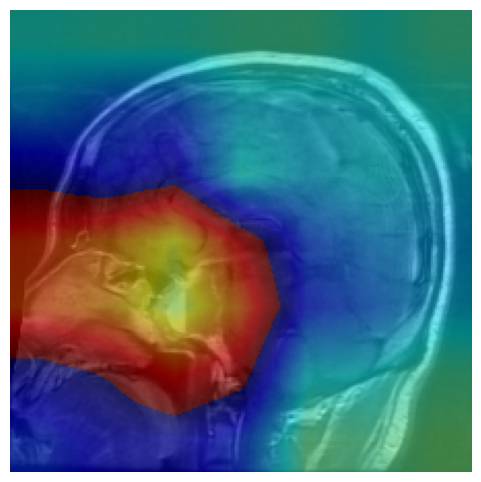

In [433]:
img_array = preprocess_image(image_path)  # 🔹 Load and preprocess the new image
heatmap = compute_gradcam(model, img_array, layer_name="block_16_project")  
overlay_heatmap(image_path, heatmap)  # 🔹 Visualize the new Grad-CAM

Found 2144 images belonging to 3 classes.
Found 458 images belonging to 3 classes.
Found 462 images belonging to 3 classes.
Epoch 1/10


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


67/67 - 75s - 1s/step - accuracy: 0.6968 - loss: 0.6963 - val_accuracy: 0.8581 - val_loss: 0.3879
Epoch 2/10
67/67 - 64s - 952ms/step - accuracy: 0.8428 - loss: 0.3966 - val_accuracy: 0.8712 - val_loss: 0.3350
Epoch 3/10
67/67 - 64s - 949ms/step - accuracy: 0.8647 - loss: 0.3401 - val_accuracy: 0.8646 - val_loss: 0.3246
Epoch 4/10
67/67 - 64s - 955ms/step - accuracy: 0.8909 - loss: 0.2911 - val_accuracy: 0.8755 - val_loss: 0.3113
Epoch 5/10
67/67 - 62s - 931ms/step - accuracy: 0.8965 - loss: 0.2599 - val_accuracy: 0.8690 - val_loss: 0.3063
Epoch 6/10
67/67 - 110s - 2s/step - accuracy: 0.9123 - loss: 0.2246 - val_accuracy: 0.8734 - val_loss: 0.2940
Epoch 7/10
67/67 - 64s - 959ms/step - accuracy: 0.9291 - loss: 0.2065 - val_accuracy: 0.8755 - val_loss: 0.2930
Epoch 8/10
67/67 - 64s - 953ms/step - accuracy: 0.9263 - loss: 0.1968 - val_accuracy: 0.8690 - val_loss: 0.2896
Epoch 9/10
67/67 - 80s - 1s/step - accuracy: 0.9310 - loss: 0.1863 - val_accuracy: 0.8734 - val_loss: 0.2886
Epoch 10/10

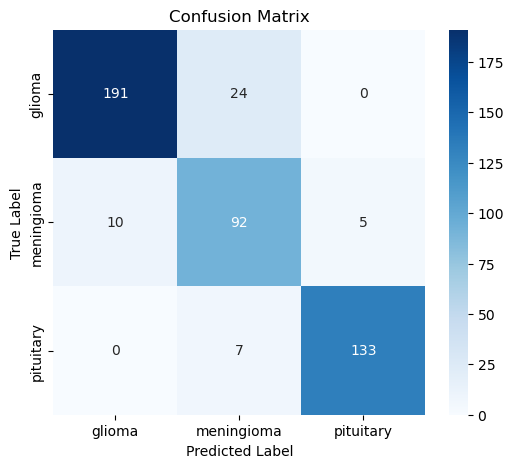

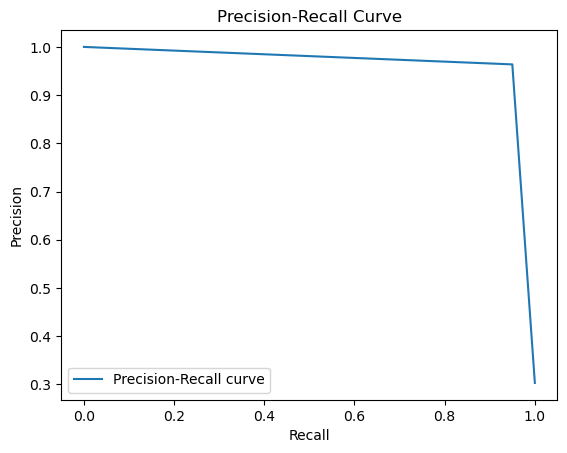

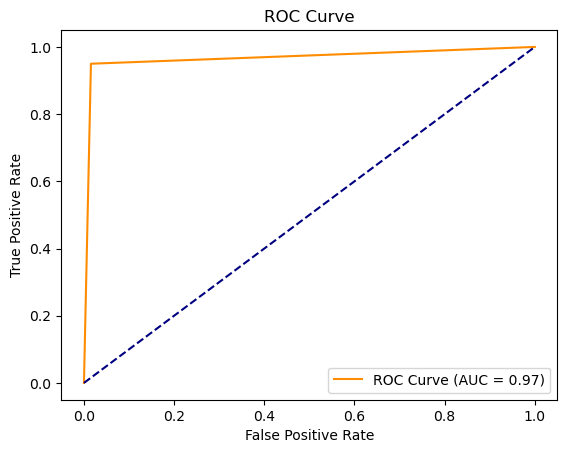

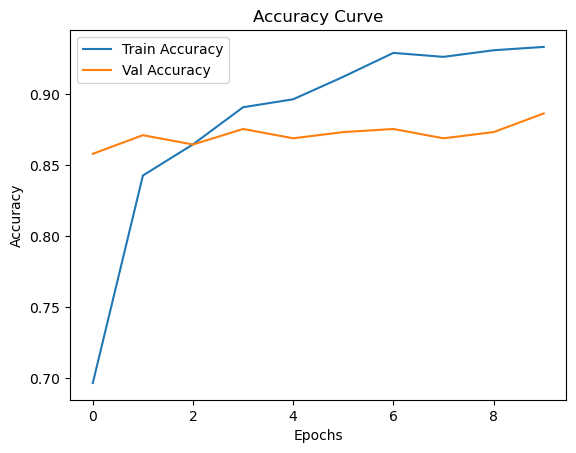

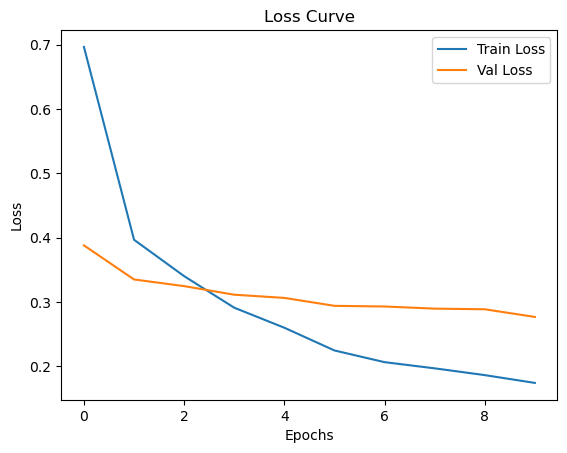

In [138]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, roc_curve, auc, confusion_matrix, classification_report
import seaborn as sns
import os

# Base data directory
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'

# Paths
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# Image parameters
img_height, img_width = 224, 224
batch_size = 32

# ImageDataGenerator (rescale only)
datagen = ImageDataGenerator(rescale=1./255)

# Load data
train_data = datagen.flow_from_directory(
    train_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True
)

val_data = datagen.flow_from_directory(
    val_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True
)

test_data = datagen.flow_from_directory(
    test_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

# Model setup
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(3, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=x)

model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train for 10 epochs only (no further training will occur after this)
history = model.fit(
    train_data,
    epochs=10,
    validation_data=val_data,
    callbacks=[early_stopping],
    verbose=2
)


# Evaluation on test set
test_loss, test_acc = model.evaluate(test_data)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Predictions
test_labels = test_data.classes
test_preds = model.predict(test_data)
test_preds = np.argmax(test_preds, axis=1)

# Confusion Matrix and Report
conf_matrix = confusion_matrix(test_labels, test_preds)
print("\nConfusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(classification_report(test_labels, test_preds, target_names=test_data.class_indices.keys()))

# Confusion Matrix Plot
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_data.class_indices.keys(),
            yticklabels=test_data.class_indices.keys())
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Precision-Recall (for class index 2, you can change)
precision, recall, _ = precision_recall_curve(test_labels == 2, test_preds == 2)
plt.figure()
plt.plot(recall, precision, label='Precision-Recall curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(test_labels == 2, test_preds == 2)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='darkorange')
plt.plot([0, 1], [0, 1], linestyle='--', color='navy')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Plot Accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [171]:
model.save('mobilenetv2 model _10 epochs.h5')  # Save the model
print("Model saved successfully!")


Model saved successfully!


In [2]:
from tensorflow.keras.models import load_model

# Load trained model
model = load_model("mobilenetv2 model _10 epochs.h5")
print("✅ Model Loaded")


✅ Model Loaded


In [ ]:
import time
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Load model
model = load_model("mobilenetv2 model _10 epochs.h5")

# Load and preprocess image
img = load_img("sample_image.jpg", target_size=(224, 224))
img = img_to_array(img) / 255.0
img = np.expand_dims(img, axis=0)

# Time inference
start = time.time()
_ = model.predict(img)
end = time.time()

print("Inference time:", (end - start) * 1000, "ms")


In [4]:
import time
import os
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# === PATHS ===
model_path = r"C:\Users\usER\Downloads\mobilenetv2 model _10 epochs.h5"
image_path = r"C:\Users\usER\Downloads\1512427\converted_images_split\test\glioma\3061.jpg"

# === Load Model ===
model = load_model(model_path)
print("✅ Model loaded successfully.")

# === Load and Preprocess Image ===
img = load_img(image_path, target_size=(224, 224))  # adjust to your model input
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)  # shape: (1, 224, 224, 3)

# === Measure Inference Time ===
start = time.time()
_ = model.predict(img_array)
end = time.time()

inference_time_ms = (end - start) * 1000
print(f"🕒 Inference Time: {inference_time_ms:.2f} ms")

# === Measure Model Size ===
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"💾 Model Size: {model_size_mb:.2f} MB")


✅ Model loaded successfully.
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
🕒 Inference Time: 2323.10 ms
💾 Model Size: 14.14 MB


Found 462 images belonging to 3 classes.


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


15/15 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.95      0.89      0.92       215
  meningioma       0.75      0.86      0.80       107
   pituitary       0.96      0.95      0.96       140

    accuracy                           0.90       462
   macro avg       0.89      0.90      0.89       462
weighted avg       0.91      0.90      0.90       462



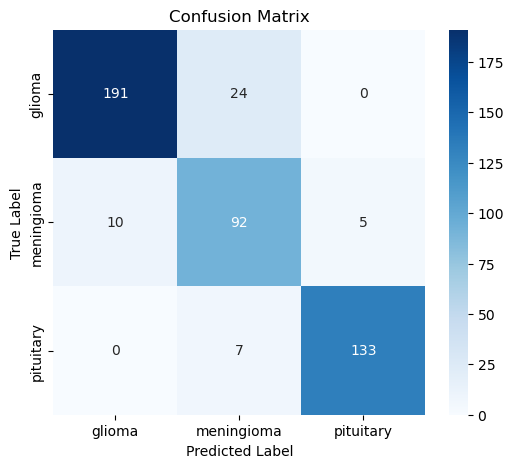

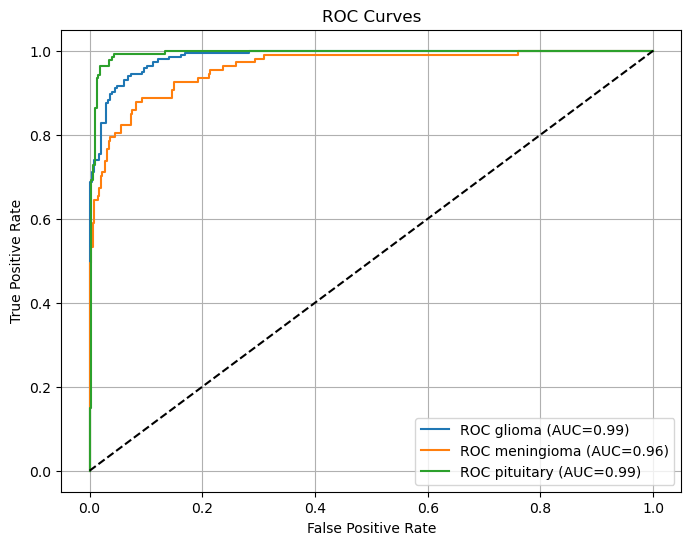

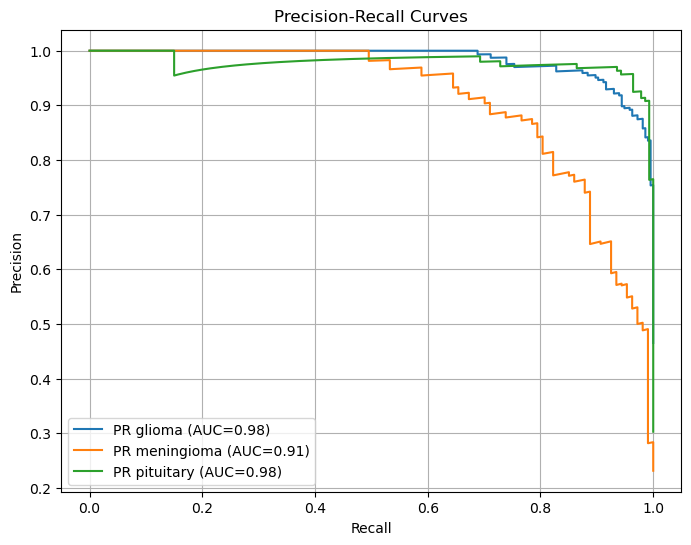

In [173]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load model
model = load_model('mobilenetv2 model _10 epochs.h5')

# Data setup
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'
test_dir = os.path.join(base_dir, 'test')
img_height, img_width = 224, 224
batch_size = 32

datagen = ImageDataGenerator(rescale=1./255)
test_data = datagen.flow_from_directory(test_dir, target_size=(img_height, img_width),
                                        batch_size=batch_size, class_mode='categorical', shuffle=False)

test_labels = test_data.classes
class_names = list(test_data.class_indices.keys())
n_classes = len(class_names)

# Predictions
test_preds = model.predict(test_data)
test_preds_labels = np.argmax(test_preds, axis=1)

# Confusion matrix & report (optional)
from sklearn.metrics import confusion_matrix, classification_report
conf_matrix = confusion_matrix(test_labels, test_preds_labels)
print("\nClassification Report:")
print(classification_report(test_labels, test_preds_labels, target_names=class_names))

# Plot Confusion Matrix (optional)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Binarize labels for multi-class metrics
y_true_bin = label_binarize(test_labels, classes=range(n_classes))

# ROC Curve and AUC per class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], test_preds[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'ROC {class_names[i]} (AUC={roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Precision-Recall Curve and AUC per class
precision = dict()
recall = dict()
pr_auc = dict()
for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], test_preds[:, i])
    pr_auc[i] = auc(recall[i], precision[i])

plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(recall[i], precision[i], label=f'PR {class_names[i]} (AUC={pr_auc[i]:.2f})')
plt.title('Precision-Recall Curves')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()


In [ ]:
model.save('final2 10 epochs _mobilenetv2_model')  # Save the model
print("Model saved successfully!")

In [159]:
from tensorflow.keras.models import load_model

# Load trained model
model = load_model("final2 10 epochs _mobilenetv2_tb_model.h5")
print("✅ Model Loaded")


✅ Model Loaded


In [160]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

# Base directory
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'
test_dir = os.path.join(base_dir, 'test')

# Image parameters
img_height, img_width = 224, 224
batch_size = 32

# Rescale test data
datagen = ImageDataGenerator(rescale=1./255)
test_data = datagen.flow_from_directory(
    test_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)


Found 462 images belonging to 3 classes.


In [161]:
# Evaluate the model
test_loss, test_acc = model.evaluate(test_data)
print(f"📊 Test Accuracy: {test_acc * 100:.2f}%")
print(f"📉 Test Loss: {test_loss:.4f}")


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


15/15 ━━━━━━━━━━━━━━━━━━━━ 14s 679ms/step - accuracy: 0.9020 - loss: 0.2165
📊 Test Accuracy: 90.04%
📉 Test Loss: 0.2459


15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 687ms/step
🔢 Precision-Recall AUC for class 2: 0.9777
📌 Max Precision: 1.0000
📌 Max Recall: 1.0000
📌 Avg Precision: 0.6579
📌 Avg Recall: 0.8431


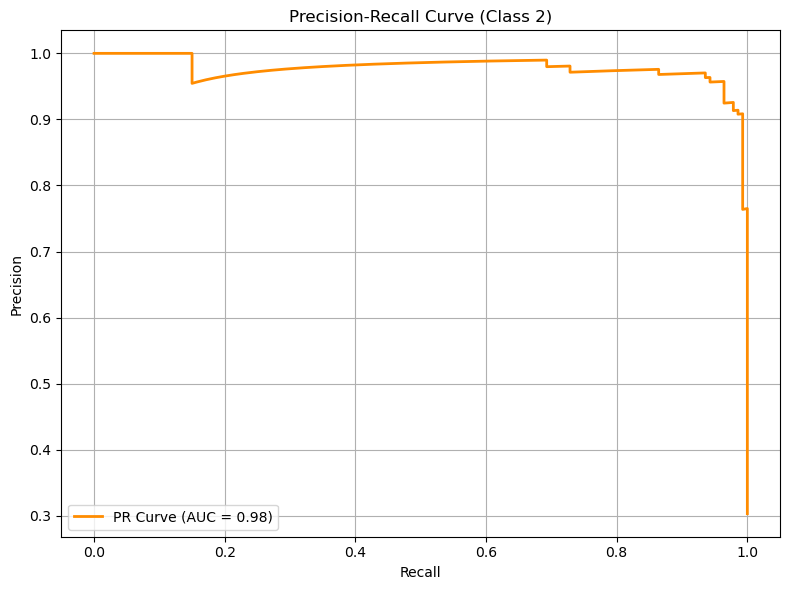

In [164]:
from sklearn.metrics import precision_recall_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# ✅ Step 1: Get true labels
true_labels = test_data.classes

# ✅ Step 2: Predict probabilities
pred_probs = model.predict(test_data)
pred_classes = np.argmax(pred_probs, axis=1)

# ✅ Step 3: Choose target class (e.g., 2)
target_class = 2
y_true = (true_labels == target_class).astype(int)
y_scores = pred_probs[:, target_class]

# ✅ Step 4: Compute Precision-Recall
precision, recall, _ = precision_recall_curve(y_true, y_scores)
pr_auc = auc(recall, precision)

# ✅ Step 5: Print metrics
print(f"🔢 Precision-Recall AUC for class {target_class}: {pr_auc:.4f}")
print(f"📌 Max Precision: {np.max(precision):.4f}")
print(f"📌 Max Recall: {np.max(recall):.4f}")
print(f"📌 Avg Precision: {np.mean(precision):.4f}")
print(f"📌 Avg Recall: {np.mean(recall):.4f}")

# ✅ Step 6: Plot Precision-Recall Curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'PR Curve (AUC = {pr_auc:.2f})', color='darkorange', lw=2)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve (Class {target_class})')
plt.legend(loc='lower left')
plt.grid(True)
plt.tight_layout()
plt.show()


15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 705ms/step


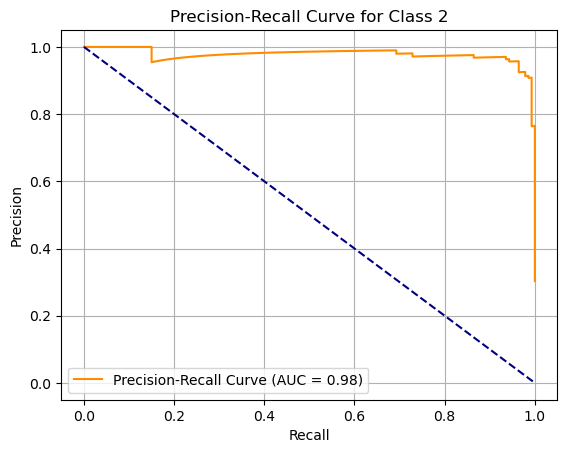

In [151]:
from sklearn.metrics import precision_recall_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# ✅ Prepare true labels and predicted probabilities
true_labels = test_data.classes
pred_probs = model.predict(test_data)
target_class = 2  # change to 0 or 1 if needed

# ✅ Binary labels and scores for the target class
y_true = (true_labels == target_class).astype(int)
y_scores = pred_probs[:, target_class]

# ✅ Compute precision, recall, AUC
precision, recall, _ = precision_recall_curve(y_true, y_scores)
pr_auc = auc(recall, precision)

# ✅ Styled Plot
plt.figure()
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {pr_auc:.2f})', color='darkorange')
plt.plot([0, 1], [1, 0], linestyle='--', color='navy')  # Optional diagonal
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve for Class {target_class}')
plt.legend()
plt.grid(True)
plt.show()
